# 02 — Sınav Takvimi Problemi

**Öğrenme hedefleri:**
1. Binary (0/1) karar değişkenlerini kullanmak
2. "Her ders tam olarak bir slota" tipi atama kısıtları yazmak
3. Çakışma kısıtlarını modellemek
4. Objective fonksiyonu değiştirmenin etkisini gözlemlemek

**Tahmini süre:** ~35 dakika

In [ ]:
import sys
if "google.colab" in sys.modules:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', 'pulp'], check=True)
    for _k in list(sys.modules):
        if _k == 'pulp' or _k.startswith('pulp.'):
            del sys.modules[_k]
    !git clone -q https://github.com/Meliksahcaliskan/ILP_Workshop.git
    sys.path.insert(0, "ILP_Workshop")

In [1]:
import pulp
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from utils.plotting import (
    show_status, plot_conflict_heatmap,
    plot_calendar_table, plot_student_slot_matrix,
    COURSE_COLORS, COURSE_GROUP
)

---
## Veri

Kurgusal bir bölümde 9 ders.  
Öğrenciler 3 sınıf grubuna ayrılmış; ağırlıklı olarak kendi sınıflarının derslerini alıyorlar.

| Grup | Öğrenciler | Kayıtlı dersler |
|------|-----------|------------------|
| 1. Sınıf (A) | 3 öğrenci | CSE101, MATH101, EE101 |
| 1. Sınıf (B) | 3 öğrenci | CSE102, MATH101, EE101 |
| 2. Sınıf (A) | 3 öğrenci | CSE201, MATH201, EE101 |
| 2. Sınıf (B) | 3 öğrenci | CSE202, MATH201, EE201 |
| 3. Sınıf (A) | 2 öğrenci | CSE301, CSE201 |
| 3. Sınıf (B) | 2 öğrenci | CSE302, CSE202 |

In [2]:
courses = ["CSE101", "CSE102", "CSE201", "CSE202", "CSE301",
           "CSE302", "MATH101", "MATH201", "EE101", "EE201"]

# Deterministik — elle tanımlanmış öğrenci kayıtları
student_enrollments = (
    [["CSE101", "MATH101", "EE101"]] * 3 +   # 1. Sınıf A
    [["CSE102", "MATH101", "EE101"]] * 3 +   # 1. Sınıf B
    [["CSE201", "MATH201", "EE101"]] * 3 +   # 2. Sınıf A
    [["CSE202", "MATH201", "EE201"]] * 3 +   # 2. Sınıf B
    [["CSE301", "CSE201"]] * 2 +             # 3. Sınıf A
    [["CSE302", "CSE202"]] * 2               # 3. Sınıf B
)

enrollment_count = {c: sum(c in s for s in student_enrollments) for c in courses}

df = pd.DataFrame({
    "Ders": courses,
    "Öğrenci Sayısı": [enrollment_count[c] for c in courses],
    "Grup": [COURSE_GROUP.get(c, "?") for c in courses]
})
print(df.to_string(index=False))
print(f"\nToplam öğrenci: {len(student_enrollments)}")

   Ders  Öğrenci Sayısı     Grup
 CSE101               3 1. Sınıf
 CSE102               3 1. Sınıf
 CSE201               5 2. Sınıf
 CSE202               5 2. Sınıf
 CSE301               2 3. Sınıf
 CSE302               2 3. Sınıf
MATH101               6 1. Sınıf
MATH201               6 2. Sınıf
  EE101               9 1. Sınıf
  EE201               3 2. Sınıf

Toplam öğrenci: 16


---
## Çakışma Isı Haritası

İki ders arasındaki ortak öğrenci sayısı:

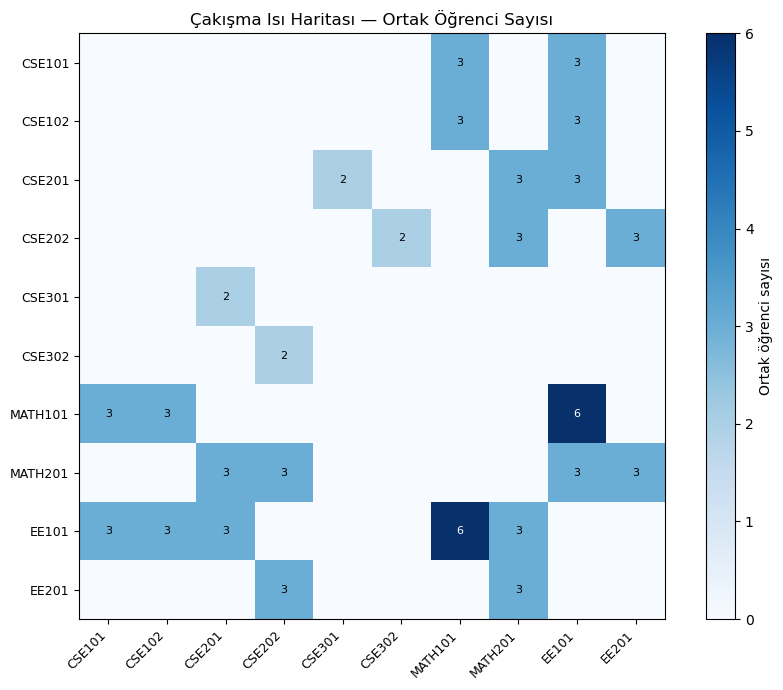

Çakışan ders çifti sayısı: 13 / 45 mümkün


In [3]:
fig = plot_conflict_heatmap(courses, student_enrollments)
plt.show()

conflict_pairs = set()
for enr in student_enrollments:
    for c1, c2 in combinations(enr, 2):
        conflict_pairs.add(tuple(sorted([c1, c2])))

print(f"Çakışan ders çifti sayısı: {len(conflict_pairs)} / {len(courses)*(len(courses)-1)//2} mümkün")

---
## ILP Modeli

**Karar değişkenleri:**
- `x[c, t] ∈ {0, 1}` — ders `c`, slot `t`'de ise 1
- `y[t] ∈ {0, 1}` — slot `t` kullanılıyorsa 1

**Amaç:** `min Σ_t y[t]`

**Kısıtlar:**
1. Her ders tam olarak bir slota: `Σ_t x[c,t] = 1`
2. Çakışan dersler aynı slotta olamaz: `x[c1,t] + x[c2,t] ≤ 1`
3. Slot bağlantısı: `x[c,t] ≤ y[t]`
4. **Simetri kırma:** `y[t] ≥ y[t+1]`

> Simetri kırma kısıtı, solver'ın aynı çözümün farklı slot numaralandırmaları arasında
> arama yapmasını önler. Slotlar her zaman Slot 0'dan itibaren ardışık dolar.

In [4]:
# Slot etiketleri: gün + oturum
SLOT_LABELS = [
    "Pzt 09:00", "Pzt 13:00", "Pzt 16:00",
    "Sal 09:00", "Sal 13:00"
]
# Aynı gün içindeki ardışık slot çiftleri (gün sınırı sayılmaz)
CONSEC_PAIRS = {(0,1), (1,2), (3,4)}  # Pzt çiftleri + Sal çifti; (2,3) gün sınırı

MAX_SLOTS = len(SLOT_LABELS)
slots = list(range(MAX_SLOTS))

prob = pulp.LpProblem("exam_scheduling", pulp.LpMinimize)

x = {(c, t): pulp.LpVariable(f"x_{c}_{t}", cat="Binary")
     for c in courses for t in slots}
y = {t: pulp.LpVariable(f"y_{t}", cat="Binary") for t in slots}

prob += pulp.lpSum(y[t] for t in slots)

for c in courses:
    prob += pulp.lpSum(x[c, t] for t in slots) == 1
for (c1, c2) in conflict_pairs:
    for t in slots:
        prob += x[c1, t] + x[c2, t] <= 1
for c in courses:
    for t in slots:
        prob += x[c, t] <= y[t]

# Simetri kırma
for t in range(MAX_SLOTS - 1):
    prob += y[t] >= y[t + 1]

prob.solve(pulp.PULP_CBC_CMD(msg=0))
show_status(prob)
print(f"Kullanılan slot sayısı: {int(pulp.value(prob.objective))}")

Kullanılan slot sayısı: 3


---
## Sonuç: Takvim Tablosu

=== Sınav Takvimi ===
  Pzt 09:00   : CSE202, EE101
  Pzt 13:00   : CSE201, CSE302, MATH101, EE201
  Pzt 16:00   : CSE101, CSE102, CSE301, MATH201


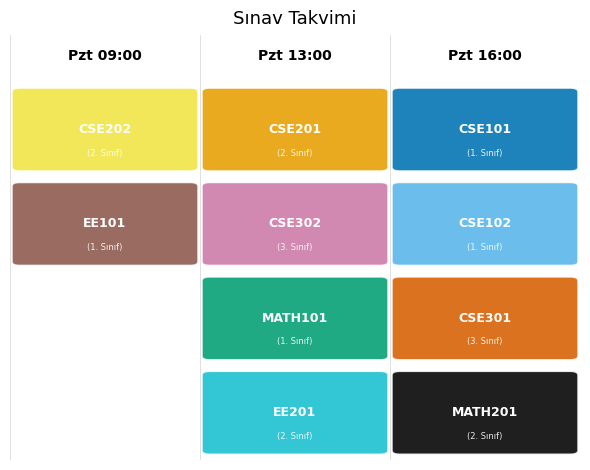

In [5]:
schedule = {}
for c in courses:
    for t in slots:
        if pulp.value(x[c, t]) > 0.5:
            schedule[c] = t

used_slots = sorted(set(schedule.values()))
print("=== Sınav Takvimi ===")
for t in used_slots:
    label = SLOT_LABELS[t] if t < len(SLOT_LABELS) else f"Slot {t+1}"
    cs = [c for c, s in schedule.items() if s == t]
    print(f"  {label:12s}: {', '.join(cs)}")

fig = plot_calendar_table(schedule, SLOT_LABELS)
plt.show()

---
## Sonuç: Öğrenci × Slot Matrisi

Her hücre: öğrencinin o slottaki sınavı.  
🔵 Normal — 🟠 Art arda — 🔴 Çakışma (**hiç olmamalı**)

In [ ]:
fig = plot_student_slot_matrix(
    schedule, student_enrollments, courses, SLOT_LABELS, CONSEC_PAIRS
)
plt.show()

# Kırmızı hücre (çakışma) kontrolü
has_conflict = False
for enr in student_enrollments:
    slots_used = [schedule[c] for c in enr if c in schedule]
    if len(slots_used) != len(set(slots_used)):
        has_conflict = True
        break
if not has_conflict:
    print("✅ Model doğrulandı: Hiçbir öğrencinin aynı slotta iki sınavı yok.")
else:
    print("❌ Çakışma tespit edildi!")

---
## 🔧 Değiştir-Gözlemle Görevleri

### Görev 1 — Hoca Kısıtı

> **Tahmin:** EE101'in Pzt 09:00 slotunda yapılamayacağını eklersen slot sayısı değişir mi?

In [ ]:
def build_base_model(name, extra_constraints=None):
    """Temel modeli kurar; extra_constraints: (x, y) -> [kısıt listesi] fonksiyonu."""
    p = pulp.LpProblem(name, pulp.LpMinimize)
    xv = {(c, t): pulp.LpVariable(f"x_{c}_{t}", cat="Binary")
          for c in courses for t in slots}
    yv = {t: pulp.LpVariable(f"y_{t}", cat="Binary") for t in slots}

    p += pulp.lpSum(yv[t] for t in slots)
    for c in courses:
        p += pulp.lpSum(xv[c, t] for t in slots) == 1
    for (c1, c2) in conflict_pairs:
        for t in slots:
            p += xv[c1, t] + xv[c2, t] <= 1
    for c in courses:
        for t in slots:
            p += xv[c, t] <= yv[t]
    for t in range(MAX_SLOTS - 1):
        p += yv[t] >= yv[t + 1]
    if extra_constraints:
        extra_constraints(xv, yv, p)
    return p, xv, yv


# Görev 1
def g1_constraints(xv, yv, p):
    p += xv["EE101", 0] == 0  # EE101 → Pzt 09:00 yasak

p_g1, x_g1, y_g1 = build_base_model("exam_g1", g1_constraints)
p_g1.solve(pulp.PULP_CBC_CMD(msg=0))
show_status(p_g1)
print(f"Slot sayısı: {int(pulp.value(p_g1.objective))}  (önceki: {int(pulp.value(prob.objective))})")

> **Eğitmen notu:** Genellikle slot sayısı değişmez — solver aynı slot planını farklı bir sıraya koyar. Çok kısıtlayıcı bir yasak eklenirse 1 artabilir.

### Görev 2 — Salon Kapasitesi

> **Tahmin:** Her slot'ta en fazla `CAPACITY` öğrenci olabilirse slot sayısı nasıl değişir?  
> `CAPACITY = 10` ile başla, sonra `8` ve `4` dene.

In [ ]:
CAPACITY = 10  # Değiştirerek dene: 8, 6, 4

def g2_constraints(xv, yv, p):
    for t in slots:
        p += pulp.lpSum(enrollment_count[c] * xv[c, t] for c in courses) <= CAPACITY

p_g2, x_g2, y_g2 = build_base_model("exam_g2", g2_constraints)
p_g2.solve(pulp.PULP_CBC_CMD(msg=0))
show_status(p_g2)
if p_g2.status == 1:
    print(f"Kapasite={CAPACITY} → Slot sayısı: {int(pulp.value(p_g2.objective))}")

> **Eğitmen notu:** `CAPACITY=10`'da slot sayısı artar (EE101'in 9 öğrencisi bir slotta yalnız kalır). `CAPACITY=4`'te **Infeasible** — en az 9 öğrencili EE101 hiçbir slota sığamaz.

### Görev 3 — Optimumdan 1 Eksik Slot

> **Tahmin:** Bulunan optimal slot sayısını 1 azaltırsak ne olur?

In [ ]:
optimal_n = int(pulp.value(prob.objective))
restricted = list(range(optimal_n - 1))

p_g3 = pulp.LpProblem("exam_g3", pulp.LpMinimize)
x3 = {(c, t): pulp.LpVariable(f"x_{c}_{t}", cat="Binary")
      for c in courses for t in restricted}
y3 = {t: pulp.LpVariable(f"y_{t}", cat="Binary") for t in restricted}

p_g3 += pulp.lpSum(y3[t] for t in restricted)
for c in courses:
    p_g3 += pulp.lpSum(x3[c, t] for t in restricted) == 1
for (c1, c2) in conflict_pairs:
    for t in restricted:
        p_g3 += x3[c1, t] + x3[c2, t] <= 1
for c in courses:
    for t in restricted:
        p_g3 += x3[c, t] <= y3[t]

p_g3.solve(pulp.PULP_CBC_CMD(msg=0))
show_status(p_g3)
print(f"Optimal: {optimal_n} slot → {optimal_n-1} slota zorlanınca: {pulp.LpStatus[p_g3.status]}")

> **Eğitmen notu:** **Infeasible**. Bu sonuç grafın kromatik sayısıyla doğrudan bağlantılıdır.

### Görev 4 — Objective Değiştir: Art Arda Sınavı Minimize Et (İleri Seviye — Eğitmen Gösterir)

Slot sayısını sabit tutup, aynı gün art arda iki sınavı olan öğrenci sayısını minimize edelim.  
Bunun için yeni binary yardımcı değişkenler gerekiyor.

In [ ]:
fixed_slots = list(range(optimal_n))

p_g4 = pulp.LpProblem("exam_g4", pulp.LpMinimize)
x4 = {(c, t): pulp.LpVariable(f"x_{c}_{t}", cat="Binary")
      for c in courses for t in fixed_slots}

# z[sid, t1, t2] = öğrenci sid, art arda (t1, t2) slotlarında sınavı var mı
z = {}
for sid, enr in enumerate(student_enrollments):
    for (t1, t2) in CONSEC_PAIRS:
        if t1 in fixed_slots and t2 in fixed_slots and len(enr) >= 2:
            z[sid, t1, t2] = pulp.LpVariable(f"z_{sid}_{t1}_{t2}", cat="Binary")

# Objective: art arda sınav sayısını minimize et
p_g4 += pulp.lpSum(z.values())

for c in courses:
    p_g4 += pulp.lpSum(x4[c, t] for t in fixed_slots) == 1
for (c1, c2) in conflict_pairs:
    for t in fixed_slots:
        p_g4 += x4[c1, t] + x4[c2, t] <= 1

# z bağlama: öğrencinin t1 ve t2'de farklı sınavları varsa z ≥ 1
for sid, enr in enumerate(student_enrollments):
    for (t1, t2) in CONSEC_PAIRS:
        if t1 not in fixed_slots or t2 not in fixed_slots:
            continue
        for c1 in enr:
            for c2 in enr:
                if c1 != c2:
                    if (sid, t1, t2) in z:
                        p_g4 += z[sid, t1, t2] >= x4[c1, t1] + x4[c2, t2] - 1

p_g4.solve(pulp.PULP_CBC_CMD(msg=0))
show_status(p_g4)

schedule_g4 = {c: t for c in courses for t in fixed_slots if pulp.value(x4[c, t]) > 0.5}
consecutive_before = sum(
    1 for enr in student_enrollments
    for (t1, t2) in CONSEC_PAIRS
    if any(schedule.get(c) == t1 for c in enr) and
       any(schedule.get(c) == t2 for c in enr if schedule.get(c) != t1)
)
consecutive_after = int(pulp.value(p_g4.objective))
print(f"Art arda sınav (önceki objective ile) : {consecutive_before}")
print(f"Art arda sınav (minimize sonrası)     : {consecutive_after}")

#### Görev 4 — Öğrenci Matrisleri: Önce / Sonra

In [ ]:
import matplotlib.pyplot as plt
from utils.plotting import plot_student_slot_matrix

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax_idx, (sched, title_suffix) in enumerate([
    (schedule,    f"Önce (art arda={consecutive_before})"),
    (schedule_g4, f"Sonra (art arda={consecutive_after})")
]):
    ax = axes[ax_idx]

    from utils.plotting import PALETTE
    used = sorted(set(sched.values()))
    col_map = {s: i for i, s in enumerate(used)}
    n_slots = len(used)
    n_students = len(student_enrollments)

    ax.set_xlim(0, n_slots); ax.set_ylim(0, n_students); ax.axis("off")
    for col, s in enumerate(used):
        lbl = SLOT_LABELS[s] if s < len(SLOT_LABELS) else f"S{s}"
        ax.text(col+0.5, n_students+0.05, lbl, ha="center", va="bottom",
                fontsize=7, fontweight="bold", rotation=30)

    for row, enr in enumerate(student_enrollments):
        y_pos = n_students - row - 1
        s_slots = {sched[c]: c for c in enr if c in sched}
        s_list = sorted(s_slots.keys())
        consec = set()
        for i in range(len(s_list)):
            for j in range(i+1, len(s_list)):
                if (s_list[i], s_list[j]) in CONSEC_PAIRS:
                    consec.add(s_list[i]); consec.add(s_list[j])

        for col, s in enumerate(used):
            bg = PALETTE["sky"] if s in s_slots else PALETTE["light"]
            if s in consec:
                bg = "#FFAA44"
            rect = plt.Rectangle((col+0.05, y_pos+0.05), 0.9, 0.85,
                                  facecolor=bg, edgecolor="white", linewidth=0.5)
            ax.add_patch(rect)
            if s in s_slots:
                ax.text(col+0.5, y_pos+0.47, s_slots[s],
                        ha="center", va="center", fontsize=6,
                        color="white", fontweight="bold")
        ax.text(-0.05, y_pos+0.47, f"Ö{row+1}", ha="right", va="center", fontsize=6)
    ax.set_title(title_suffix, fontsize=10)

plt.suptitle("Öğrenci × Slot — Art Arda Sınav Karşılaştırması", fontsize=12)
plt.tight_layout()
plt.show()

> **Eğitmen notu:** Turuncu hücre sayısı azalmalı; sıfıra inilebilirse her öğrencinin günde en fazla bir sınavı var demektir. Gün sınırı (Pzt 16:00 → Sal 09:00) ardışık **sayılmaz** — `CONSEC_PAIRS` tanımına dikkat edin.

---
## 📎 Ek: Bu Problemin Teorik Adı — Graph Coloring

Çakışma grafı: Düğüm = ders, kenar = ortak öğrenci.  
Farklı renk ataması = farklı slot ataması.  
**Minimum renk sayısı = kromatik sayı = minimum slot sayısı.**

In [ ]:
import networkx as nx
import matplotlib.patches as mpatches
from utils.plotting import COURSE_COLORS, PALETTE

G = nx.Graph()
G.add_nodes_from(courses)
G.add_edges_from(conflict_pairs)

pos = nx.spring_layout(G, seed=7)
node_colors = [COURSE_COLORS.get(c, PALETTE["gray"]) for c in G.nodes()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: düğümler sınıf grubuna göre renkli
from utils.plotting import GROUP_COLOR, COURSE_GROUP
group_colors = [GROUP_COLOR.get(COURSE_GROUP.get(c, ""), PALETTE["gray"]) for c in G.nodes()]

nx.draw_networkx(G, pos=pos, ax=axes[0], node_color=group_colors, node_size=700,
                 font_color="white", font_size=8, font_weight="bold",
                 edge_color="gray", alpha=0.9)
legend_h = [mpatches.Patch(color=v, label=k) for k, v in GROUP_COLOR.items()]
axes[0].legend(handles=legend_h, fontsize=8)
axes[0].set_title("Çakışma Grafı — Sınıf Grupları"); axes[0].axis("off")

# Sağ: optimal renklendirme (slot'a göre)
palette_list = [PALETTE["blue"], PALETTE["orange"], PALETTE["green"],
                PALETTE["sky"], PALETTE["vermil"]]
slot_colors  = [palette_list[schedule.get(c, 0) % len(palette_list)] for c in G.nodes()]

nx.draw_networkx(G, pos=pos, ax=axes[1], node_color=slot_colors, node_size=700,
                 font_color="white", font_size=8, font_weight="bold",
                 edge_color="gray", alpha=0.9)
used_slots = sorted(set(schedule.values()))
legend_s = [mpatches.Patch(color=palette_list[t % len(palette_list)],
                            label=SLOT_LABELS[t] if t < len(SLOT_LABELS) else f"Slot {t}")
            for t in used_slots]
axes[1].legend(handles=legend_s, fontsize=8)
axes[1].set_title(f"Renklendirilmiş Graf — {len(used_slots)} renk = {len(used_slots)} slot")
axes[1].axis("off")

plt.suptitle("Graph Coloring ↔ Sınav Takvimi  |  Register Allocation da aynı yapıya sahip!",
             fontsize=10)
plt.tight_layout()
plt.show()